# Original Generating Prompt:

I want to check if quantization / vector scaling is data independent. Generate me the corresponding python script. For this I must:

Setup:
1. Download an encoder that has been trained to do matrioska scaling

2. Download two separate datasets, targeting different relevant fields (for example health and law)
3. Run the datasets through the encoder at the most expensive encoding possible (Max vector len, 64 bits). Save the processed datasets in two different datastores.
4. Generate, execute and save 10 random queries for each field.
5. For each query, save the top 10 nearest results, from the corresponding datastore.

These query results, would serve as landmarks (best possible).

Experiment:
1. for vector_len in vector_lens :


2. for quantization in quantization_lens :

3. for dataset in datasets :

4.
    1. Translate dataset to this (vector_len, quantization) space through the encoder

    2. retreive original 10 queries for this dataset. Execute them through the encoder

    3. For each query, match the top 10 results with the nearest equivalent of the original

    4. Sum up the distance from the 100 original results to the 100 query counterparts

    5. Store the results in array[dataset][vector_len][quantization]

5. for dataset in datasets :
    1. plot(vector_len, quantization, array[dataset][vector_len][quantization])
    2. calculate average of distance

Conclusion :

print the two distances. Let's see if they're different.

Don't forget to add printing in between exection steps.
This script will be pasted in a new notebook kernel. You can add the commands as such.

# Importing requirements

In [3]:
!pip install sentence-transformers datasets faiss-cpu matplotlib seaborn numpy pandas

In [4]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
import random

# Setup

In [5]:
# ==========================================
# SETUP
# ==========================================
print("--- Starting Setup ---")

# 1. Load a native Matryoshka Representation Learning (MRL) model
print("Loading MRL Encoder...")
model = SentenceTransformer("tomaarsen/mpnet-base-nli-matryoshka")
max_dim = 768

# 2. Download two distinct datasets (Health vs Law/Politics)
print("Loading Datasets...")
# We strictly use fully-namespaced, natively-parquet datasets.
# This prevents both the HfUriError (missing namespace) and the trust_remote_code blockers.
ds_health = load_dataset("medalpaca/medical_meadow_medical_flashcards", split="train[:500]")
ds_law = load_dataset("SetFit/bbc-news", split="train[:500]")

def get_text_col(ds):
    """Safely extracts a text column regardless of the dataset schema."""
    for col in ['text', 'output', 'content', 'document', 'input']:
        if col in ds.column_names:
            return ds[col]
    return ds[ds.column_names[-1]] # fallback to the last column

datasets_dict = {
    "health": get_text_col(ds_health),
    "law": get_text_col(ds_law)
}

# 3. Generate Landmarks (Max vector len, float32)
print("Encoding base datasets at max resolution (768, float32)...")
base_embeddings = {}
faiss_indices = {}

for name, texts in datasets_dict.items():
    # Convert to standard python strings to ensure FAISS compatibility
    texts = [str(t) for t in texts]
    embs = model.encode(texts, convert_to_numpy=True, normalize_embeddings=True)
    base_embeddings[name] = embs

    # Build FAISS index for exact search (L2 distance on normalized vectors = Cosine Similarity)
    index = faiss.IndexFlatL2(max_dim)
    index.add(embs)
    faiss_indices[name] = index

# 4. Generate 10 random queries for each field
print("Generating queries and saving landmarks...")
np.random.seed(42)
queries_dict = {}
landmarks = {} # stores top 10 indices for each query

for name, texts in datasets_dict.items():
    # Pick 10 random documents to act as queries
    texts_list = [str(t) for t in texts]
    query_texts = random.sample(texts_list, 10)
    q_embs = model.encode(query_texts, convert_to_numpy=True, normalize_embeddings=True)
    queries_dict[name] = {"texts": query_texts, "embs": q_embs}

    # 5. Save top 10 nearest results (Landmarks)
    distances, indices = faiss_indices[name].search(q_embs, 10)
    landmarks[name] = indices


--- Starting Setup ---
Loading MRL Encoder...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading Datasets...
Encoding base datasets at max resolution (768, float32)...
Generating queries and saving landmarks...


# Executing the experiment

In [6]:

# ==========================================
# EXPERIMENT
# ==========================================
print("\n--- Starting Experiment ---")

vector_lens = [768, 512, 256, 128, 64]
quantizations = ['float32', 'int8', 'binary']

# array[dataset][vector_len][quantization]
results_array = {name: {v: {q: 0 for q in quantizations} for v in vector_lens} for name in datasets_dict.keys()}

def apply_quantization(embs, quant_type):
    """Simulates quantization degradation."""
    if quant_type == 'float32':
        return embs.astype(np.float32)
    elif quant_type == 'int8':
        # Scale to -128 to 127
        scaled = np.clip(embs * 127.0, -128, 127).astype(np.int8)
        return scaled.astype(np.float32) # Convert back to float for faiss math
    elif quant_type == 'binary':
        # Binarize (x > 0 = 1, else -1 for cosine retention)
        return np.where(embs > 0, 1.0, -1.0).astype(np.float32)

for v_len in vector_lens:
    print(f"\nEvaluating Vector Length: {v_len}")

    for q_type in quantizations:
        print(f"  Quantization: {q_type}")

        for dataset_name in datasets_dict.keys():
            # 1. Translate dataset to (vector_len, quantization) space
            truncated_base = base_embeddings[dataset_name][:, :v_len]
            quantized_base = apply_quantization(truncated_base, q_type)

            # Rebuild index for the degraded space
            idx = faiss.IndexFlatL2(v_len)
            idx.add(quantized_base)

            # 2. Retrieve original 10 queries, truncate and quantize
            truncated_queries = queries_dict[dataset_name]["embs"][:, :v_len]
            quantized_queries = apply_quantization(truncated_queries, q_type)

            # 3. Match top 10 results
            new_distances, new_indices = idx.search(quantized_queries, 10)

            # 4. Calculate distance/degradation from original landmarks
            total_distance = 0
            for i in range(10): # 10 queries
                original_set = set(landmarks[dataset_name][i])
                new_set = set(new_indices[i])
                overlap = len(original_set.intersection(new_set))
                error = 10 - overlap # Distance from ideal
                total_distance += error

            # 5. Store results
            results_array[dataset_name][v_len][q_type] = total_distance



--- Starting Experiment ---

Evaluating Vector Length: 768
  Quantization: float32
  Quantization: int8
  Quantization: binary

Evaluating Vector Length: 512
  Quantization: float32
  Quantization: int8
  Quantization: binary

Evaluating Vector Length: 256
  Quantization: float32
  Quantization: int8
  Quantization: binary

Evaluating Vector Length: 128
  Quantization: float32
  Quantization: int8
  Quantization: binary

Evaluating Vector Length: 64
  Quantization: float32
  Quantization: int8
  Quantization: binary


# Extracting the Conclusion


--- Plotting & Conclusion ---


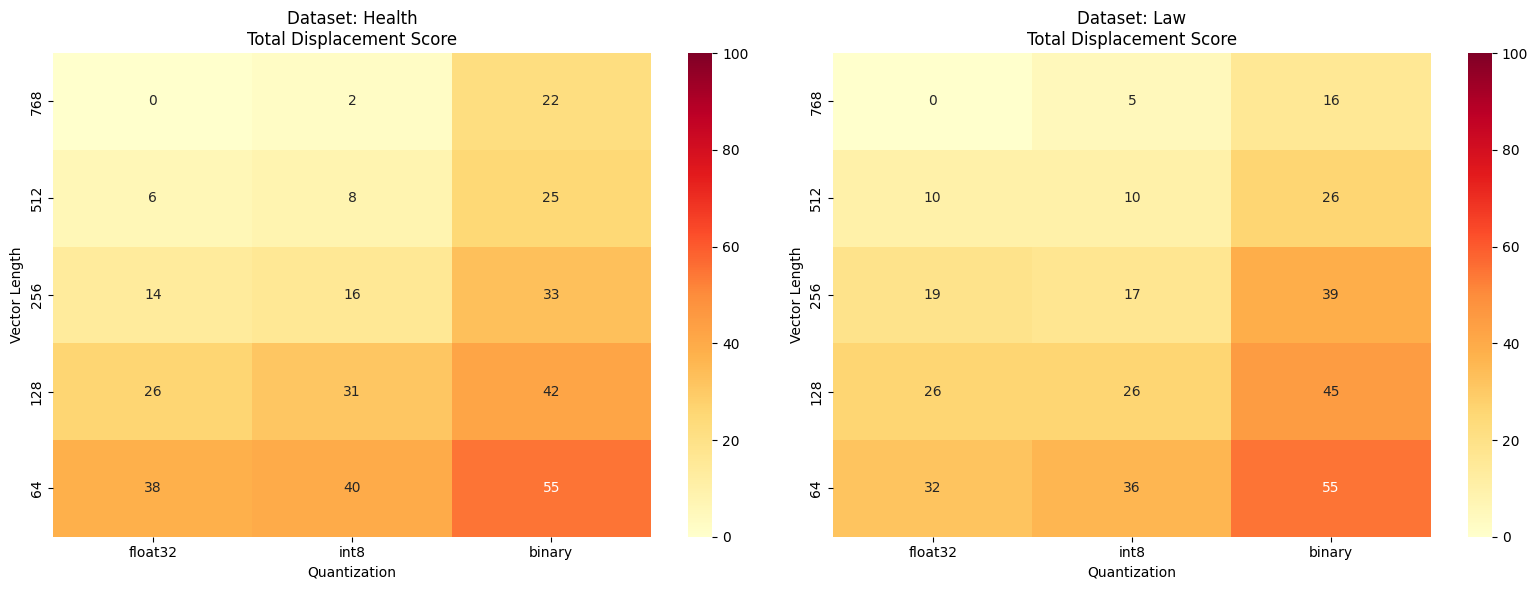


--- Final Results ---
Average retrieval error (Health): 23.87 / 100 possible displacement
Average retrieval error (Law): 24.13 / 100 possible displacement

Difference in degradation across datasets: 0.27
Conclusion: The degradation profiles are very similar. Matryoshka/Quantization scaling appears to be relatively DATA INDEPENDENT.


In [7]:

# ==========================================
# CONCLUSION & PLOTTING
# ==========================================
print("\n--- Plotting & Conclusion ---")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

average_distances = {}

for i, (dataset_name, data) in enumerate(results_array.items()):
    # Convert nested dict to 2D numpy array for heatmap
    matrix = np.zeros((len(vector_lens), len(quantizations)))
    total_dataset_error = 0

    for v_idx, v_len in enumerate(vector_lens):
        for q_idx, q_type in enumerate(quantizations):
            error_val = data[v_len][q_type]
            matrix[v_idx, q_idx] = error_val
            total_dataset_error += error_val

    # Calculate average distance across all configurations for this dataset
    avg_error = total_dataset_error / (len(vector_lens) * len(quantizations))
    average_distances[dataset_name] = avg_error

    # Plotting
    sns.heatmap(matrix, annot=True, xticklabels=quantizations, yticklabels=vector_lens,
                ax=axes[i], cmap="YlOrRd", vmin=0, vmax=100)
    axes[i].set_title(f"Dataset: {dataset_name.capitalize()}\nTotal Displacement Score")
    axes[i].set_xlabel("Quantization")
    axes[i].set_ylabel("Vector Length")

plt.tight_layout()
plt.show()

print("\n--- Final Results ---")
print(f"Average retrieval error (Health): {average_distances['health']:.2f} / 100 possible displacement")
print(f"Average retrieval error (Law): {average_distances['law']:.2f} / 100 possible displacement")

diff = abs(average_distances['health'] - average_distances['law'])
print(f"\nDifference in degradation across datasets: {diff:.2f}")
if diff > 5.0:
    print("Conclusion: The degradation profiles are significantly different. Matryoshka/Quantization scaling appears to be highly DATA DEPENDENT.")
else:
    print("Conclusion: The degradation profiles are very similar. Matryoshka/Quantization scaling appears to be relatively DATA INDEPENDENT.")